# 03 · Regresión por edición

La pregunta del TFM es cómo ha cambiado entre 2012 y 2022 la relación del compromiso del alumno y de sus recursos de estudio con su nota de matemáticas, según el perfil de su centro. Este notebook la responde con una regresión lineal por edición sobre la tabla de `02_preparacion_modelo`:

* ¿Cuánta nota se asocia a una desviación típica más de compromiso y de recursos de estudio en cada edición, de media en todos los perfiles? (sección 1)
* ¿Y en cada perfil de centro? (sección 2)
* ¿Son distintas las pendientes entre perfiles dentro de una edición? (sección 3)
* ¿Han cambiado entre 2012 y 2022, y de forma distinta según el perfil? (sección 4)

**El modelo.** Para cada edición, la nota de matemáticas de un alumno es

nota = α_país + δ_perfil + β_perfil · compromiso + γ_perfil · recursos de estudio + controles + error

* **α_país** es el efecto fijo de país: un indicador por país que absorbe todo lo que distingue a un país de otro (nivel de nota, sistema educativo, forma de responder al cuestionario). Las pendientes se estiman solo comparando alumnos del mismo país.
* **δ_perfil** es la diferencia de nota media de cada perfil frente a `PUB_URB_MED` (el perfil con más centros), con los mismos controles.
* **β_perfil** y **γ_perfil** son las pendientes de cada perfil: los puntos de nota que se asocian a una desviación típica más de la variable dentro de ese perfil. En la sección 1 son una sola pendiente para todos.
* **Controles**: origen social (ocupación y estudios de los padres, riqueza del hogar y libros en casa), sexo, inmigración, composición social y dotación del centro, con sus indicadores de «sin dato» (`02_preparacion_modelo`, sección 3), con una pendiente común a todos los perfiles.

Se pondera con `SENWT` (cada país pesa lo mismo), los errores típicos se agrupan por centro (los alumnos de un centro se parecen entre sí); `03_errores_brr` comprueba que dan casi lo mismo que los pesos replicados (BRR) con los que PISA calcula los suyos y la regresión se repite con cada valor plausible de la nota (5 en 2012, 10 en las demás) y se combina con las reglas de Rubin (`src/modelo_regresion.py`). Las variables están tipificadas con las cuatro ediciones juntas, así que una pendiente se compara directamente entre ediciones.

**Qué no dice.** Es una asociación, no un efecto causal: un alumno con más compromiso puede diferir en cosas que el modelo no mide. Vale para los alumnos que tienen las dos variables de interés (`02_preparacion_modelo`, sección 2); en 2018, para los que contestaron el cuestionario opcional de deberes. Y en el nivel del índice de compromiso entre ediciones influye el tamaño del tercil central de deberes (`01_EDA_indice_de_compromiso_competencia`, sección 5.7.4), aunque su pendiente dentro de cada edición no depende de eso.

## 0. Configuración

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.modelo_regresion import PERFIL_REFERENCIA, contraste_igualdad, estimar_con_rubin, matriz_diseno
from src.preparacion_modelo import CONTROLES, DE_INTERES, matriz_regresion

pd.set_option('display.width', 200)

EDICIONES = [2012, 2015, 2018, 2022]
RUTA_PROCESADOS = '../../data/processed'
RUTA_MODELOS = '../../models'
RUTA_REPORTS = '../../reports'
NOMBRES = {'Indice_Compromiso_Competencia': 'compromiso', 'recursos_estudio': 'recursos de estudio'}
COLORES_EDICION = dict(zip(EDICIONES, plt.cm.Blues(np.linspace(0.4, 0.95, len(EDICIONES)))))

# Alumnos del modelo: variables continuas tipificadas y huecos de los controles rellenados con la media y un indicador
tabla = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'tabla_modelo_alumno.parquet'))
parametros = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'parametros_escala.parquet'))
matriz = matriz_regresion(tabla, parametros)
PERFILES = sorted(matriz['perfil'].unique())
# Si cada perfil-edición tiene menos de 30 centros
poco_representativo = tabla[tabla['en_modelo']].groupby(['perfil', 'year'])['perfil_poco_representativo'].first()
print(f"{len(matriz)} alumnos de {matriz['CNT'].nunique()} países y {len(PERFILES)} perfiles; por edición:", matriz.groupby('year').size().to_dict())

298782 alumnos de 12 países y 15 perfiles; por edición: {2012: 73843, 2015: 68795, 2018: 69878, 2022: 86266}


## 1. Pendiente común por edición

Primero, una sola pendiente de compromiso y de recursos de estudio para todos los perfiles: la relación media en cada edición, con el efecto fijo de país y los controles. Se dan también las pendientes de los controles, para tener una referencia del tamaño. El cambio de 2012 a 2022 se contrasta como la diferencia de dos estimaciones independientes (muestras distintas), con error típico √(ET²₂₀₁₂ + ET²₂₀₂₂).

**Puntos de matemáticas por desviación típica (por 1 en las variables de 0 o 1); entre paréntesis, error típico**

year,2012,2015,2018,2022
variable,,,,
Indice_Compromiso_Competencia,10.64 (0.51),9.84 (0.44),11.51 (0.49),12.12 (0.45)
recursos_estudio,5.44 (0.53),5.62 (0.57),4.93 (0.58),5.9 (0.47)
HISEI_TREND,9.31 (0.61),9.37 (0.5),8.63 (0.56),7.9 (0.47)
PAREDINT_TREND,-0.44 (0.51),-0.47 (0.59),-0.21 (0.6),-1.64 (0.48)
riqueza_hogar,0.23 (0.5),0.08 (0.53),0.11 (0.5),0.59 (0.46)
libros,20.79 (0.56),19.85 (0.55),17.54 (0.54),16.75 (0.49)
sexo_femenino,-15.49 (1.08),-15.58 (1.11),-14.75 (1.0),-19.83 (0.89)
inmigrante,-2.32 (1.99),-4.39 (1.93),-1.67 (1.92),3.53 (1.62)
composicion_social_centro,31.13 (1.1),23.75 (0.98),28.59 (1.12),31.84 (1.01)


Cambio de 2012 a 2022 de la pendiente común:
                                 2012    2022  cambio  error_tipico  valor_p
variable                                                                    
Indice_Compromiso_Competencia  10.639  12.120   1.481         0.678    0.029
recursos_estudio                5.444   5.901   0.458         0.702    0.514

% de la varianza de las pendientes de interés que viene de los valores plausibles:
year                           2012  2015  2018  2022
variable                                             
Indice_Compromiso_Competencia  11.6  18.1  28.7  12.7
recursos_estudio               12.1  47.0  42.5  13.0


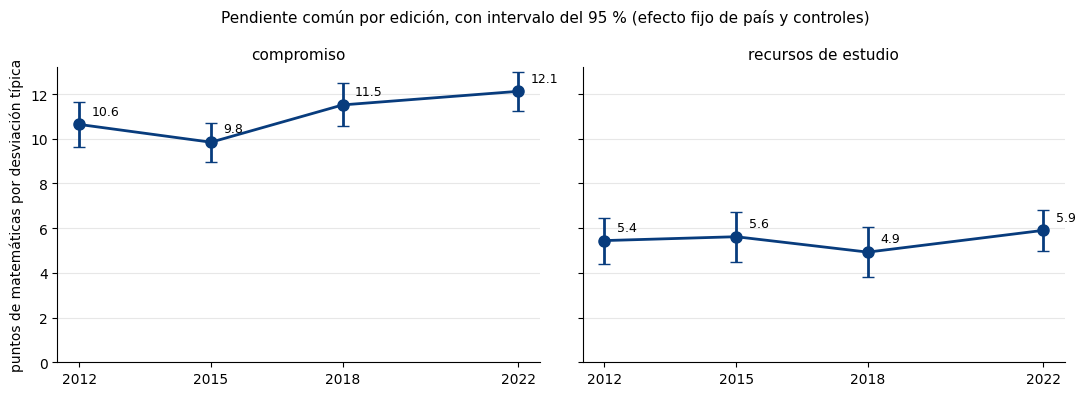

In [2]:
# Modelo de pendiente común: una regresión por edición, combinando los valores plausibles con Rubin
comun = {}
for edicion in EDICIONES:
    datos_edicion = matriz[matriz['year'] == edicion].reset_index(drop=True)
    comun[edicion], _ = estimar_con_rubin(datos_edicion, matriz_diseno(datos_edicion, por_perfil=False))
comun = pd.concat(comun, names=['year', 'variable'])

# Pendientes por edición, con su error típico
pendientes = comun['coeficiente'].unstack('year').loc[DE_INTERES + CONTROLES]
errores = comun['error_tipico'].unstack('year').loc[DE_INTERES + CONTROLES]
display(Markdown('**Puntos de matemáticas por desviación típica (por 1 en las variables de 0 o 1); entre paréntesis, error típico**'))
display(pendientes.round(2).astype(str) + ' (' + errores.round(2).astype(str) + ')')

# Cambio de 2012 a 2022: las dos ediciones son muestras independientes, así que sus varianzas se suman
cambio = pd.DataFrame({'2012': pendientes.loc[DE_INTERES, 2012], '2022': pendientes.loc[DE_INTERES, 2022],
                       'cambio': pendientes.loc[DE_INTERES, 2022] - pendientes.loc[DE_INTERES, 2012],
                       'error_tipico': np.sqrt(errores.loc[DE_INTERES, 2012] ** 2 + errores.loc[DE_INTERES, 2022] ** 2)})
cambio['valor_p'] = 2 * stats.norm.sf(np.abs(cambio['cambio'] / cambio['error_tipico']))
print('Cambio de 2012 a 2022 de la pendiente común:')
print(cambio.round(3))
print('\n% de la varianza de las pendientes de interés que viene de los valores plausibles:')
print(comun['% varianza entre PV'].unstack('year').loc[DE_INTERES].round(1))

# Figura: pendiente común por edición
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, variable in zip(ejes, DE_INTERES):
    fila = comun.xs(variable, level='variable')
    eje.errorbar(EDICIONES, fila['coeficiente'], yerr=1.96 * fila['error_tipico'], color=COLORES_EDICION[2022], marker='o', markersize=8,
                 linewidth=2, capsize=4)
    for edicion, valor in fila['coeficiente'].items():
        eje.annotate(f'{valor:.1f}', (edicion, valor), textcoords='offset points', xytext=(9, 7), fontsize=9)
    eje.set_title(f'{NOMBRES[variable]}', fontsize=11)
    eje.set_xticks(EDICIONES)
    eje.set_ylim(0, None)
    eje.grid(axis='y', alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_ylabel('puntos de matemáticas por desviación típica')
fig.suptitle('Pendiente común por edición, con intervalo del 95 % (efecto fijo de país y controles)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_regresion_pendiente_comun.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **El compromiso es la variable de interés con más relación con la nota.** Una desviación típica más de compromiso se asocia a 10,64 puntos más de matemáticas en 2012, 9,84 en 2015, 11,51 en 2018 y 12,12 en 2022, siempre comparando alumnos del mismo país y con el mismo origen social.
* **La relación del compromiso se refuerza algo de 2012 a 2022**: 1,48 puntos más por desviación típica (error típico 0,68, p = 0,029). Es un cambio pequeño frente al nivel de la pendiente, y no es una subida continua: 2015 está por debajo de 2012.
* **Los recursos de estudio se asocian a unos 5 o 6 puntos por desviación típica, estables**: 5,44 en 2012, 5,62, 4,93 y 5,90 en 2022. El cambio de 2012 a 2022 (0,46) no se distingue de cero (p = 0,514). Por cada recurso más, son entre 5,25 y 6,28 puntos (sección 5).
* **Referencias del tamaño, con los controles.**
  * Los libros en casa (entre 16,75 y 20,79 puntos por desviación típica) y la composición social del centro (entre 23,75 y 31,84) pesan más que las dos variables de interés.
  * La ocupación de los padres pesa entre 7,90 y 9,37.
  * La dotación del centro queda entre −2,49 y −3,70, como en `01_EDA_recursos_centro`.
  * Las chicas sacan entre 14,75 y 19,83 puntos menos que los chicos con lo demás igual.
* **Los valores plausibles importan**: aportan entre el 11,6 % y el 28,7 % de la varianza de la pendiente del compromiso, y hasta el 47,0 % en la de los recursos (2015). Usar uno solo daría errores típicos demasiado pequeños.

## 2. Pendientes por perfil

Ahora cada perfil tiene su propia pendiente de compromiso y de recursos de estudio (los controles siguen siendo comunes). En el gráfico, cada fila es un perfil y cada punto una edición, con su intervalo del 95 %; los puntos huecos son perfiles-edición con menos de 30 centros (`perfil_poco_representativo`), que no se interpretan. Los perfiles se ordenan por titularidad, ubicación y tamaño.

**compromiso**: pendiente por perfil (puntos por desviación típica); `*` = perfil-edición poco representativo

year,2012,2015,2018,2022
perfil,,,,
CON_RUR_MACRO,9.6,12.4*,15.0*,15.9
CON_RUR_MED,12.7*,12.1*,15.2,13.4
CON_RUR_PEQ,8.7,11.0,9.9,13.4
CON_URB_MACRO,11.3,12.8,13.5,12.7
CON_URB_MED,10.0,9.1,7.7,13.3
CON_URB_PEQ,5.4,13.3,9.8,8.6
PRI_URB_MACRO,16.8,11.2,13.2,15.2
PRI_URB_MED,6.8,9.1*,19.5,11.9
PRI_URB_PEQ,9.7,2.1*,3.9,14.2


Sin los poco representativos, mínimo y máximo por edición:
year             2012         2015         2018           2022
min          5.385486     8.676389     3.855294       8.591448
idxmin    CON_URB_PEQ  PUB_RUR_MED  PRI_URB_PEQ    CON_URB_PEQ
max         16.839557    13.335336    19.483273      15.915608
idxmax  PRI_URB_MACRO  CON_URB_PEQ  PRI_URB_MED  CON_RUR_MACRO


**recursos de estudio**: pendiente por perfil (puntos por desviación típica); `*` = perfil-edición poco representativo

year,2012,2015,2018,2022
perfil,,,,
CON_RUR_MACRO,6.8,1.4*,7.3*,9.4
CON_RUR_MED,-3.6*,2.7*,11.1,-1.0
CON_RUR_PEQ,6.5,3.2,7.0,12.0
CON_URB_MACRO,4.9,1.1,2.5,5.6
CON_URB_MED,4.7,8.4,5.6,6.1
CON_URB_PEQ,6.2,3.6,11.2,4.2
PRI_URB_MACRO,3.4,6.5,2.6,17.6
PRI_URB_MED,3.9,3.4*,2.7,6.0
PRI_URB_PEQ,9.4,-2.2*,0.2,6.0


Sin los poco representativos, mínimo y máximo por edición:
year             2012           2015         2018           2022
min           3.38978       1.145945     0.175912      -1.045531
idxmin  PRI_URB_MACRO  CON_URB_MACRO  PRI_URB_PEQ    CON_RUR_MED
max           9.39586       8.426288    11.244304      17.645383
idxmax    PRI_URB_PEQ    CON_URB_MED  CON_URB_PEQ  PRI_URB_MACRO


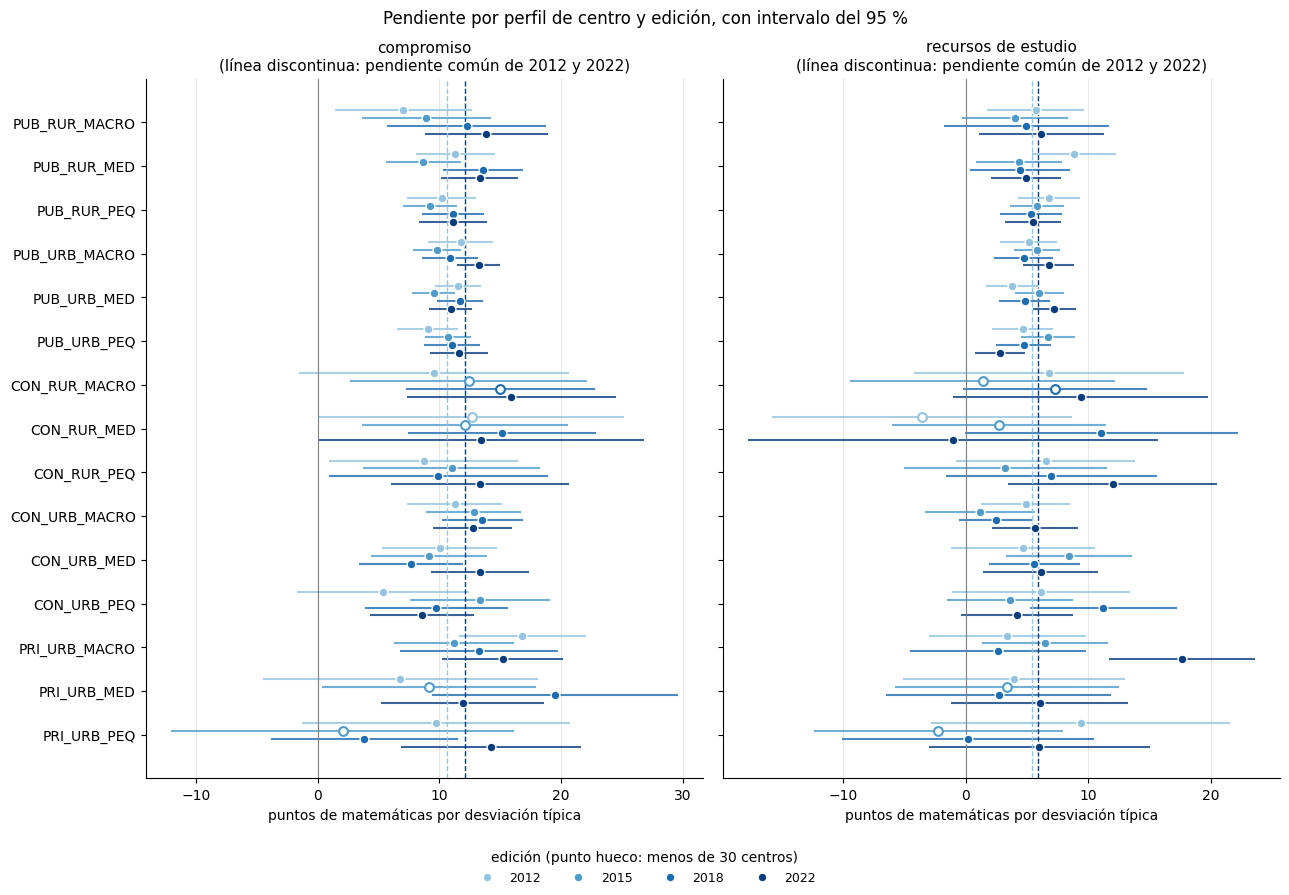

In [3]:
# Modelo con una pendiente por perfil; se guardan las covarianzas para los contrastes
por_perfil, covarianzas = {}, {}
for edicion in EDICIONES:
    datos_edicion = matriz[matriz['year'] == edicion].reset_index(drop=True)
    por_perfil[edicion], covarianzas[edicion] = estimar_con_rubin(datos_edicion, matriz_diseno(datos_edicion, por_perfil=True))
por_perfil = pd.concat(por_perfil, names=['year', 'termino'])

# Solo las pendientes por perfil (términos `<variable>:<perfil>`), con su marca de poco representativo y sus alumnos
pendientes_perfil = por_perfil[por_perfil.index.get_level_values('termino').str.contains(':')].reset_index()
pendientes_perfil[['variable', 'perfil']] = pendientes_perfil['termino'].str.split(':', expand=True)
pendientes_perfil['poco_representativo'] = [poco_representativo[(perfil, edicion)] for perfil, edicion in zip(pendientes_perfil['perfil'], pendientes_perfil['year'])]
alumnos_perfil = matriz.groupby(['perfil', 'year']).size().rename('alumnos')
pendientes_perfil = pendientes_perfil.merge(alumnos_perfil, left_on=['perfil', 'year'], right_index=True)

# Tabla de pendientes por perfil y edición, y los perfiles extremos sin contar los poco representativos
for variable in DE_INTERES:
    tabla_variable = pendientes_perfil[pendientes_perfil['variable'] == variable].pivot(index='perfil', columns='year', values='coeficiente')
    display(Markdown(f'**{NOMBRES[variable]}**: pendiente por perfil (puntos por desviación típica); `*` = perfil-edición poco representativo'))
    marcas = pendientes_perfil[pendientes_perfil['variable'] == variable].pivot(index='perfil', columns='year', values='poco_representativo')
    display(tabla_variable.round(1).astype(str) + marcas.replace({True: '*', False: ''}))
    resumen = tabla_variable.where(~marcas)
    print('Sin los poco representativos, mínimo y máximo por edición:')
    print(resumen.agg(['min', 'idxmin', 'max', 'idxmax']))

# Perfiles ordenados por titularidad, ubicación y tamaño
orden = sorted(PERFILES, key=lambda perfil: (['PUB', 'CON', 'PRI'].index(perfil.split('_')[0]), perfil.split('_')[1], ['MACRO', 'MED', 'PEQ'].index(perfil.split('_')[2])))
# Figura: pendiente de cada perfil por edición (punto hueco: poco representativo)
fig, ejes = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
desplazamiento = dict(zip(EDICIONES, np.linspace(-0.27, 0.27, len(EDICIONES))))
for eje, variable in zip(ejes, DE_INTERES):
    filas = pendientes_perfil[pendientes_perfil['variable'] == variable]
    for edicion in EDICIONES:
        de_edicion = filas[filas['year'] == edicion].set_index('perfil').loc[orden]
        posicion = np.arange(len(orden)) + desplazamiento[edicion]
        eje.errorbar(de_edicion['coeficiente'], posicion, xerr=1.96 * de_edicion['error_tipico'], fmt='none', ecolor=COLORES_EDICION[edicion], elinewidth=1.5, alpha=0.8)
        fiable = ~de_edicion['poco_representativo'].to_numpy()
        eje.scatter(de_edicion['coeficiente'][fiable], posicion[fiable], color=COLORES_EDICION[edicion], s=40, label=str(edicion), zorder=3, edgecolor='white', linewidth=1)
        eje.scatter(de_edicion['coeficiente'][~fiable], posicion[~fiable], facecolor='white', edgecolor=COLORES_EDICION[edicion], s=40, zorder=3, linewidth=1.5)
    comun_variable = comun.xs(variable, level='variable')['coeficiente']
    eje.axvline(0, color='grey', linewidth=0.8)
    eje.set_title(f'{NOMBRES[variable]}\n(línea discontinua: pendiente común de 2012 y 2022)', fontsize=11)
    for edicion in (2012, 2022):
        eje.axvline(comun_variable[edicion], color=COLORES_EDICION[edicion], linestyle='--', linewidth=1)
    eje.set_xlabel('puntos de matemáticas por desviación típica')
    eje.grid(axis='x', alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_yticks(np.arange(len(orden)), orden)
ejes[0].invert_yaxis()
manejadores, etiquetas = ejes[1].get_legend_handles_labels()
fig.legend(manejadores, etiquetas, title='edición (punto hueco: menos de 30 centros)', loc='lower center', ncol=len(EDICIONES), fontsize=9, frameon=False)
fig.suptitle('Pendiente por perfil de centro y edición, con intervalo del 95 %', fontsize=12)
plt.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(f'{RUTA_REPORTS}/03_regresion_pendientes_perfil.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **Las pendientes del compromiso se parecen entre perfiles.**
  * En 2012 van de 5,4 puntos (`CON_URB_PEQ`) a 16,8 (`PRI_URB_MACRO`).
  * En 2022 van de 8,6 (`CON_URB_PEQ`) a 15,9 (`CON_RUR_MACRO`).
  * Casi todos los intervalos se cruzan con la pendiente común.
  * Los públicos, con muchos más centros, tienen intervalos estrechos y pendientes de 7 a 14 puntos en todas las ediciones.
* **Los recursos de estudio también se parecen, salvo en 2022.** Entonces destaca el privado urbano grande (`PRI_URB_MACRO`, 17,6 puntos), frente a entre 4 y 7 en la mayoría y 2,8 en el público urbano pequeño.
* **Los perfiles pequeños tienen intervalos muy anchos** (los concertados rurales y los privados urbanos mediano y pequeño, en el gráfico). Sus pendientes de una edición a otra cambian sobre todo por azar.

## 3. ¿Son distintas las pendientes entre perfiles?

Con 15 pendientes por variable y edición, alguna saldrá distinta de las demás por azar. Por eso, antes de comparar perfiles uno a uno, se contrasta en cada edición si las 15 pendientes son todas iguales (contraste de Wald con la matriz de covarianzas de Rubin, 14 grados de libertad). Se repite sin los perfiles-edición poco representativos.

In [4]:
# Contraste de Wald de que las pendientes de todos los perfiles son iguales, en cada edición, con y sin los poco representativos
filas = []
for edicion in EDICIONES:
    coeficientes = por_perfil.xs(edicion, level='year')['coeficiente']
    for variable in DE_INTERES:
        for sin_pocos in (False, True):
            perfiles = [perfil for perfil in PERFILES if not (sin_pocos and poco_representativo[(perfil, edicion)])]
            estadistico, grados, valor_p = contraste_igualdad(coeficientes, covarianzas[edicion], [f'{variable}:{perfil}' for perfil in perfiles])
            filas.append({'year': edicion, 'variable': NOMBRES[variable], 'perfiles': 'fiables' if sin_pocos else 'todos',
                          'estadístico': estadistico, 'grados de libertad': grados, 'valor_p': valor_p})
igualdad = pd.DataFrame(filas).set_index(['variable', 'perfiles', 'year'])
display(igualdad.round(3))

estadístico  grados de libertad  valor_p
variable            perfiles year                                          
compromiso          todos    2012       13.300                  14    0.503
                    fiables  2012       13.144                  13    0.437
recursos de estudio todos    2012       11.172                  14    0.673
                    fiables  2012        8.870                  13    0.783
compromiso          todos    2015        8.315                  14    0.872
                    fiables  2015        6.194                  10    0.799
recursos de estudio todos    2015       13.476                  14    0.489
                    fiables  2015        8.545                  10    0.576
compromiso          todos    2018       17.602                  14    0.225
                    fiables  2018       16.596                  13    0.218
recursos de estudio todos    2018       10.741                  14    0.706
                    fiables  2018       10.152                  13    0.681
compromiso          todos    2022       11.006                  14    0.686
                    fiables  2022       11.006                  14    0.686
recursos de estudio todos    2022       32.449                  14    0.003
                    fiables  2022       32.449                  14    0.003

**Qué se ve.**

* **La pendiente del compromiso es la misma en todos los perfiles, en cada edición**: no se rechaza la igualdad en ninguna (p entre 0,225 y 0,872), con o sin los perfiles poco representativos.
* **La de los recursos de estudio también es igual en 2012, 2015 y 2018** (p entre 0,489 y 0,706), pero **no en 2022** (p = 0,003): ese año la relación de los recursos con la nota depende del perfil del centro.

## 4. ¿Han cambiado las pendientes entre 2012 y 2022?

Para cada perfil, la pendiente de 2022 menos la de 2012, con su intervalo del 95 % (estimaciones independientes). Se contrasta además si el cambio es el mismo en todos los perfiles: si no lo es, la relación ha evolucionado de forma distinta según el tipo de centro, que es la pregunta del TFM. Se excluyen los perfiles poco representativos en 2012 o en 2022 (`CON_RUR_MED` en 2012).

Perfiles que no entran en la comparación: ['CON_RUR_MED']
compromiso: ¿el cambio es igual en los 14 perfiles? Wald = 7.93 con 13 gl, p = 0.848
  cambio medio (sin ponderar) 2.87; perfiles con cambio distinto de 0 al 5 %: 0 de 14
recursos de estudio: ¿el cambio es igual en los 14 perfiles? Wald = 23.94 con 13 gl, p = 0.032
  cambio medio (sin ponderar) 1.41; perfiles con cambio distinto de 0 al 5 %: 2 de 14


2012    2022  cambio  error_tipico  valor_p
variable            perfil                                                      
compromiso          CON_RUR_MACRO   9.554  15.916   6.362         7.166    0.375
                    CON_RUR_PEQ     8.710  13.356   4.646         5.450    0.394
                    CON_URB_MACRO  11.263  12.742   1.479         2.600    0.570
                    CON_URB_MED    10.022  13.336   3.314         3.155    0.293
                    CON_URB_PEQ     5.385   8.591   3.206         4.234    0.449
                    PRI_URB_MACRO  16.840  15.205  -1.634         3.683    0.657
                    PRI_URB_MED     6.787  11.940   5.153         6.697    0.442
                    PRI_URB_PEQ     9.741  14.248   4.507         6.763    0.505
                    PUB_RUR_MACRO   7.046  13.871   6.824         3.868    0.078
                    PUB_RUR_MED    11.308  13.309   2.001         2.315    0.387
                    PUB_RUR_PEQ    10.207  11.116   0.909         2.037    0.655
                    PUB_URB_MACRO  11.774  13.233   1.459         1.643    0.375
                    PUB_URB_MED    11.525  10.929  -0.596         1.306    0.648
                    PUB_URB_PEQ     9.042  11.654   2.612         1.757    0.137
recursos de estudio CON_RUR_MACRO   6.824   9.377   2.553         7.744    0.742
                    CON_RUR_PEQ     6.531  12.015   5.484         5.727    0.338
                    CON_URB_MACRO   4.889   5.629   0.740         2.582    0.774
                    CON_URB_MED     4.676   6.109   1.433         3.840    0.709
                    CON_URB_PEQ     6.156   4.176  -1.980         4.394    0.652
                    PRI_URB_MACRO   3.390  17.645  14.256         4.471    0.001
                    PRI_URB_MED     3.938   6.035   2.098         5.916    0.723
                    PRI_URB_PEQ     9.396   6.007  -3.389         7.757    0.662
                    PUB_RUR_MACRO   5.711   6.171   0.460         3.310    0.890
                    PUB_RUR_MED     8.816   4.918  -3.898         2.268    0.086
                    PUB_RUR_PEQ     6.802   5.510  -1.292         1.745    0.459
                    PUB_URB_MACRO   5.150   6.760   1.610         1.591    0.312
                    PUB_URB_MED     3.749   7.237   3.488         1.411    0.013
                    PUB_URB_PEQ     4.639   2.789  -1.850         1.637    0.258

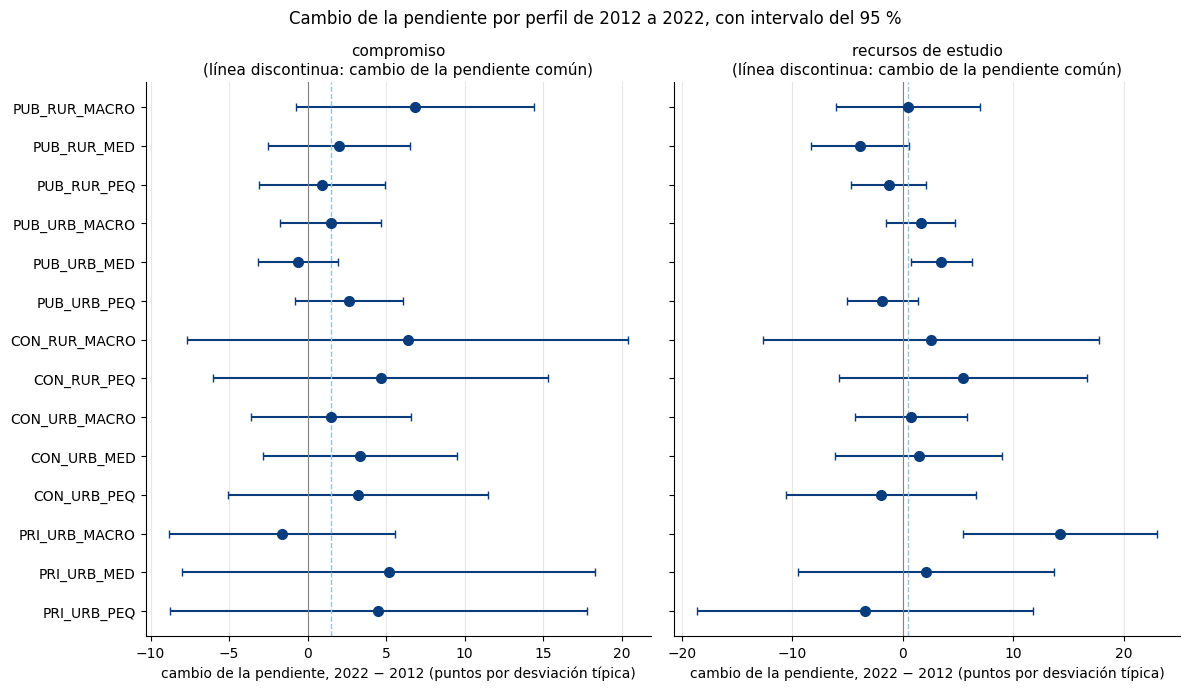

In [5]:
inicio, final = 2012, 2022
# Solo entran los perfiles con al menos 30 centros en 2012 y en 2022
fiables = [perfil for perfil in PERFILES if not poco_representativo[(perfil, inicio)] and not poco_representativo[(perfil, final)]]
print('Perfiles que no entran en la comparación:', sorted(set(PERFILES) - set(fiables)))
cambios = []
for variable in DE_INTERES:
    # Cambio de cada perfil y su varianza (suma de las de las dos ediciones)
    nombres = [f'{variable}:{perfil}' for perfil in fiables]
    diferencia = por_perfil.xs(final, level='year').loc[nombres, 'coeficiente'] - por_perfil.xs(inicio, level='year').loc[nombres, 'coeficiente']
    varianza = covarianzas[final].loc[nombres, nombres] + covarianzas[inicio].loc[nombres, nombres]
    error = np.sqrt(np.diag(varianza))
    cambios.append(pd.DataFrame({'variable': variable, 'perfil': fiables, inicio: por_perfil.xs(inicio, level='year').loc[nombres, 'coeficiente'].to_numpy(),
                                 final: por_perfil.xs(final, level='year').loc[nombres, 'coeficiente'].to_numpy(), 'cambio': diferencia.to_numpy(),
                                 'error_tipico': error, 'valor_p': 2 * stats.norm.sf(np.abs(diferencia.to_numpy() / error))}))
    # ¿El cambio es el mismo en todos los perfiles?
    estadistico, grados, valor_p = contraste_igualdad(diferencia, varianza, nombres)
    print(f'{NOMBRES[variable]}: ¿el cambio es igual en los {len(fiables)} perfiles? Wald = {estadistico:.2f} con {grados} gl, p = {valor_p:.3f}')
    print(f'  cambio medio (sin ponderar) {diferencia.mean():.2f}; perfiles con cambio distinto de 0 al 5 %: {(cambios[-1]["valor_p"] < 0.05).sum()} de {len(fiables)}')
cambios = pd.concat(cambios, ignore_index=True)
display(cambios.assign(variable=cambios['variable'].map(NOMBRES)).set_index(['variable', 'perfil']).round(3))

# Figura: cambio de la pendiente de cada perfil
fig, ejes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
orden_fiables = [perfil for perfil in orden if perfil in fiables]
for eje, variable in zip(ejes, DE_INTERES):
    filas = cambios[cambios['variable'] == variable].set_index('perfil').loc[orden_fiables]
    posicion = np.arange(len(orden_fiables))
    eje.errorbar(filas['cambio'], posicion, xerr=1.96 * filas['error_tipico'], fmt='o', color=COLORES_EDICION[2022], markersize=7, elinewidth=1.5, capsize=3)
    cambio_comun = comun.xs(final, level='year').loc[variable, 'coeficiente'] - comun.xs(inicio, level='year').loc[variable, 'coeficiente']
    eje.axvline(0, color='grey', linewidth=0.8)
    eje.axvline(cambio_comun, color=COLORES_EDICION[2012], linestyle='--', linewidth=1)
    eje.set_title(f'{NOMBRES[variable]}\n(línea discontinua: cambio de la pendiente común)', fontsize=11)
    eje.set_xlabel('cambio de la pendiente, 2022 − 2012 (puntos por desviación típica)')
    eje.grid(axis='x', alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_yticks(np.arange(len(orden_fiables)), orden_fiables)
ejes[0].invert_yaxis()
fig.suptitle('Cambio de la pendiente por perfil de 2012 a 2022, con intervalo del 95 %', fontsize=12)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_regresion_cambio_perfil.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **El refuerzo del compromiso es igual en todos los perfiles.** No se rechaza que el cambio sea el mismo en los 14 perfiles comparables (p = 0,848). Ningún perfil cambia por sí solo de forma distinguible de cero: el cambio medio es de 2,87 puntos, pero los intervalos de cada perfil son anchos. El refuerzo de la pendiente común (sección 1) es, por tanto, general, no propio de un tipo de centro.
* **En los recursos de estudio el cambio sí es distinto según el perfil** (p = 0,032), por dos perfiles:
  * el **privado urbano grande** pasa de 3,39 a 17,65 puntos (+14,26, p = 0,001), que sigue siendo significativo si se exige el 5 % repartido entre los 14 perfiles (0,05 / 14 = 0,0036);
  * el **público urbano mediano** pasa de 3,75 a 7,24 (+3,49, p = 0,013), que no resiste esa exigencia.
* **Con 28 contrastes por perfil, uno o dos saldrían al 5 % por azar.** Por eso cuenta más el contraste conjunto que cada perfil suelto, y el resultado del privado urbano grande necesita las comprobaciones de robustez antes de darlo por bueno. En particular, el efecto techo de los recursos de estudio: si en esos centros casi todos los alumnos tienen los seis recursos, la pendiente sale de pocos alumnos.

## 5. Guardado

Se guardan los coeficientes de los dos modelos, ya combinados con las reglas de Rubin, en `models/coeficientes_regresion.csv` (el formato de `models/README.md`). Una fila por edición, especificación, coeficiente y unidad:

* **`especificacion`**: `pendiente_comun` (sección 1) o `pendiente_por_perfil` (sección 2).
* **`tipo`**:
  * `principal`: la constante, los controles, sus indicadores `sin_<variable>` y, en `pendiente_comun`, las dos variables de interés. `perfil` va vacío.
  * `efecto_fijo_perfil`: la diferencia de nota de cada perfil (`perfil`) frente al de referencia, `PUB_URB_MED`, que no tiene fila. `variable` es `perfil`.
  * `pendiente_perfil`: en `pendiente_por_perfil`, la pendiente de cada variable de interés en cada perfil (`perfil`), incluido el de referencia.
* **Los efectos fijos de país no se guardan**: solo sirven para comparar alumnos del mismo país.
* **`unidad`**: `tipificada` (puntos por desviación típica, como se estima el modelo) u `original` (puntos por unidad de la variable). Las variables tipificadas tienen las dos filas: la `original` divide el coeficiente, el error y el intervalo por la desviación típica de `parametros_escala.parquet`. La constante y las variables de 0 o 1 solo tienen la fila `original`.
* Además del coeficiente, el error típico (agrupado por centro, con la varianza entre valores plausibles), el intervalo del 95 % y el valor p: el % de la varianza que viene de los valores plausibles, el número de valores plausibles, los alumnos (del perfil-edición en las filas con perfil; de la edición en el resto) y la marca de perfil poco representativo.

In [6]:
# Desviación típica de cada variable tipificada, para pasar los coeficientes a unidades originales
desviacion = parametros[parametros['edicion'] == 'todas'].set_index('variable')['desviacion_tipica']
alumnos_edicion = matriz.groupby('year').size()
alumnos_perfil = matriz.groupby(['year', 'perfil']).size()
# Una fila por coeficiente de los dos modelos, sin los efectos fijos de país, clasificada por tipo
partes = []
for especificacion, estimacion in (('pendiente_comun', comun), ('pendiente_por_perfil', por_perfil)):
    filas = estimacion.reset_index()
    filas.columns = ['edicion', 'termino'] + list(filas.columns[2:])
    filas = filas[~filas['termino'].str.startswith('pais_')].copy()
    de_perfil = filas['termino'].str.startswith('perfil_')
    pendiente = filas['termino'].str.contains(':')
    filas['tipo'] = np.select([de_perfil, pendiente], ['efecto_fijo_perfil', 'pendiente_perfil'], 'principal')
    filas['variable'] = np.where(de_perfil, 'perfil', filas['termino'].str.split(':').str[0])
    filas['perfil'] = filas['termino'].str.removeprefix('perfil_').where(de_perfil, filas['termino'].str.split(':').str[1]).astype(object)
    filas['especificacion'] = especificacion
    partes.append(filas)
coeficientes = pd.concat(partes, ignore_index=True)
# Alumnos y marca de poco representativo: los del perfil para sus términos, los de la edición para los demás
con_perfil = coeficientes['perfil'].notna()
coeficientes['alumnos'] = [alumnos_perfil[(edicion, perfil)] if propio else alumnos_edicion[edicion]
                           for edicion, perfil, propio in zip(coeficientes['edicion'], coeficientes['perfil'], con_perfil)]
coeficientes['poco_representativo'] = [bool(poco_representativo[(perfil, edicion)]) if propio else False
                                       for edicion, perfil, propio in zip(coeficientes['edicion'], coeficientes['perfil'], con_perfil)]
coeficientes = coeficientes.rename(columns={'inferior_95': 'ic_inf', 'superior_95': 'ic_sup', 'valor_p': 'p_valor',
                                            '% varianza entre PV': 'porcentaje_varianza_entre_pv'})
# Cada coeficiente de una variable tipificada se guarda también en unidades originales (dividido por su desviación típica)
tipificadas = coeficientes['variable'].isin(desviacion.index)
coeficientes['unidad'] = np.where(tipificadas, 'tipificada', 'original')
originales = coeficientes[tipificadas].copy()
escala = originales['variable'].map(desviacion)
for columna in ['coeficiente', 'error_tipico', 'ic_inf', 'ic_sup']:
    originales[columna] = originales[columna] / escala
coeficientes = pd.concat([coeficientes, originales.assign(unidad='original')], ignore_index=True)
coeficientes = coeficientes[['edicion', 'especificacion', 'tipo', 'variable', 'perfil', 'unidad', 'coeficiente', 'error_tipico', 'ic_inf', 'ic_sup', 'p_valor',
                             'porcentaje_varianza_entre_pv', 'valores_plausibles', 'alumnos', 'poco_representativo']]
os.makedirs(RUTA_MODELOS, exist_ok=True)
ruta = os.path.join(RUTA_MODELOS, 'coeficientes_regresion.csv')
coeficientes.to_csv(ruta, index=False)
print(f'{len(coeficientes)} filas en {ruta}')
print('Filas por especificación, tipo y unidad:')
print(coeficientes.groupby(['especificacion', 'tipo', 'unidad']).size())
print('Perfil de referencia (sin fila de efecto fijo):', sorted(set(PERFILES) - set(coeficientes.loc[coeficientes['tipo'] == 'efecto_fijo_perfil', 'perfil'])))
print('Puntos por unidad original de la pendiente común:')
comunes = coeficientes[(coeficientes['tipo'] == 'principal') & coeficientes['variable'].isin(DE_INTERES) & (coeficientes['unidad'] == 'original')]
print(comunes.pivot(index='variable', columns='edicion', values='coeficiente').round(2))

536 filas en ../../models\coeficientes_regresion.csv
Filas por especificación, tipo y unidad:
especificacion        tipo                unidad    
pendiente_comun       efecto_fijo_perfil  original       56
                      principal           original       68
                                          tipificada     32
pendiente_por_perfil  efecto_fijo_perfil  original       56
                      pendiente_perfil    original      120
                                          tipificada    120
                      principal           original       60
                                          tipificada     24
dtype: int64
Perfil de referencia (sin fila de efecto fijo): ['PUB_URB_MED']
Puntos por unidad original de la pendiente común:
edicion                         2012  2015   2018   2022
variable                                                
Indice_Compromiso_Competencia  10.67  9.87  11.54  12.15
recursos_estudio                5.80  5.98   5.25   6.28


**Qué se ve.** Se guardan 536 filas: 156 del modelo con pendiente común y 380 del modelo con pendiente por perfil, contando las dos unidades de las variables tipificadas. Cada modelo tiene 56 efectos fijos de perfil (14 perfiles por 4 ediciones), y el de pendiente por perfil, 240 pendientes de perfil (2 variables, 15 perfiles, 4 ediciones y 2 unidades). El perfil de referencia es `PUB_URB_MED`. En unidades originales, la pendiente común del compromiso es de 9,87 a 12,15 puntos por unidad del índice, y la de los recursos de estudio, de 5,25 a 6,28 puntos por recurso.

## Hallazgos

* **El compromiso se asocia a unos 10-12 puntos de matemáticas por desviación típica**, entre alumnos del mismo país y con el mismo origen social, el doble que los recursos de estudio (unos 5-6 puntos).
* **La relación del compromiso con la nota se refuerza ligeramente de 2012 a 2022**: de 10,64 a 12,12 puntos (+1,48, p = 0,029). El refuerzo es igual en todos los perfiles de centro: no hay diferencias entre perfiles ni en la pendiente de cada edición ni en su cambio.
* **La relación de los recursos de estudio es estable de media** (de 5,44 a 5,90, sin cambio distinguible). En 2012, 2015 y 2018 es igual en todos los perfiles, pero en 2022 deja de serlo (p = 0,003).
* **El cambio de 2022 se concentra en el privado urbano grande**: su pendiente pasa de 3,39 a 17,65 puntos. Es el único cambio por perfil que resiste la corrección por comparaciones múltiples. Hay que comprobarlo antes de interpretarlo, empezando por el efecto techo de los recursos de estudio en esos centros.
* **Respuesta provisional a la pregunta del TFM**:
  * el compromiso pesa algo más en 2022 que en 2012, en todos los tipos de centro por igual;
  * los recursos de estudio pesan lo mismo de media, con una posible excepción en los privados urbanos grandes.

**Siguientes pasos (comprobaciones de robustez)**:

* los tres componentes del índice por separado y el compromiso sin deberes (absentismo e impuntualidad), con casi toda la muestra;
* los recursos de estudio por tramos (efecto techo) y con la puntuación IRT, que además recupera alumnos en 2022;
* la escasez del centro y el `ESCS` medio del centro como controles alternativos;
* el panel ampliado de 25 países sin 2018;
* XGBoost con SHAP sobre la misma muestra, para ver si hay relaciones no lineales que la regresión no recoge.